# Latih & Validasi Model IBU_HAMIL

**Pemilik:** Muz · **Algoritma:** Logistic Regression multinomial (label 0 tidak sesuai / 1 cukup / 2 sangat sesuai)

Notebook ini menggantikan `latih_ibu_hamil.py` dan `validasi_ibu_hamil.py`. Kode training, fitur, hyperparameter, dan seed
sama untuk keempat kategori (`shared/training.py`); yang khusus kategori ada di `ibu_hamil/ai_models/`
(`profil.py`, `rubrik.py`, `bahaya.py`, `skenario.py`).

**Skema evaluasi**

| Tahap | Data | Tujuan |
|---|---|---|
| Validasi silang GroupKFold 5 lipatan | 80% profil (data latih) | skor latih vs validasi per lipatan, cek overfitting, kurva belajar |
| Test set (held-out) | 20% profil baru + 15% makanan baru | estimasi akhir yang jujur, dipakai **sekali** untuk model final |

Split dilakukan **per profil**: profil yang sama tidak pernah muncul di data latih dan validasi/test sekaligus.

**Cara menjalankan:** buka di VS Code / JupyterLab / Colab, lalu *Run All*. Hugging Face Space tetap menjalankan
`app.py` (API); notebook ini hanya untuk melatih model dan membuat laporan. Model hasil latih disimpan ke
`ibu_hamil/model/recommender_IBU_HAMIL.joblib` dan dipakai API.

In [1]:
import os, sys

# Cari root repo (folder yang berisi model.py) agar notebook bisa dijalankan dari folder mana pun
ROOT = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(ROOT, 'model.py')):
    if os.path.dirname(ROOT) == ROOT:
        raise RuntimeError('Root repo (model.py) tidak ditemukan. Jalankan notebook dari dalam repo.')
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, ROOT)
os.chdir(ROOT)
os.environ.setdefault('AI_ALLOW_SNAPSHOT_FALLBACK', '1')   # uji end-to-end memakai snapshot bila Supabase offline

KATEGORI = 'IBU_HAMIL'
BUAT_DATA = False      # True = buat ulang dataset sintetis dari profil.py & rubrik.py kategori ini
JUMLAH_PROFIL = 700

import pandas as pd
from IPython.display import Markdown, display
from shared import PEMILIK, data_dir
from shared import grafik
from shared.pipeline import latih_kategori, validasi_kategori

pd.set_option('display.width', 160)
print(f'Model {KATEGORI} | pemilik {PEMILIK[KATEGORI]} | root {ROOT}')

Model IBU_HAMIL | pemilik Muz | root D:\Semester 6\Proyek Perangkat Lunak I\AINutriScale\ai_recommendation_railway


## 1. Dataset sintetis

,baris,profil,makanan unik,baris makanan baru
Latih,33586,560,7024,0
Test,8396,140,5013,1263


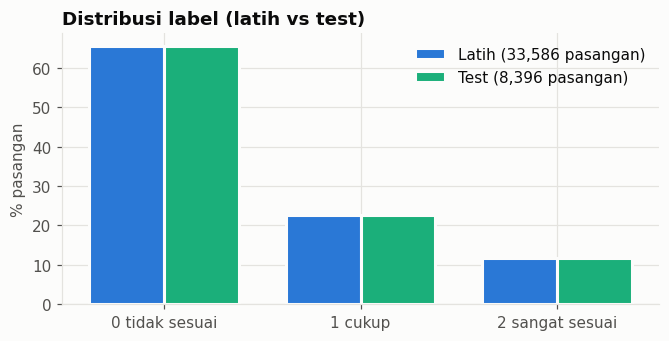

In [2]:
if BUAT_DATA:
    from shared.dataset import generate_category_dataset, load_food_catalog
    generate_category_dataset(load_food_catalog(os.path.join(ROOT, 'data', 'nutrition.csv')), KATEGORI, JUMLAH_PROFIL)

df_train = pd.read_csv(os.path.join(data_dir(KATEGORI), 'train_data.csv'))
df_test = pd.read_csv(os.path.join(data_dir(KATEGORI), 'test_data.csv'))
display(pd.DataFrame({
    'baris': [len(df_train), len(df_test)],
    'profil': [df_train['profile_id'].nunique(), df_test['profile_id'].nunique()],
    'makanan unik': [df_train['food_name'].nunique(), df_test['food_name'].nunique()],
    'baris makanan baru': [int(df_train['is_new_food'].sum()), int(df_test['is_new_food'].sum())],
}, index=['Latih', 'Test']))
grafik.distribusi_label(df_train, df_test)

## 2. Latih model

Validasi silang, model final, pembanding gradient boosting, dan kurva belajar (sekitar 1-2 menit).

In [3]:
h = latih_kategori(KATEGORI)

  NUTRISCALE AI — MODEL IBU_HAMIL (pemilik: Muz)
  Logistic Regression multinomial | skor = (P(cukup) + 2 * P(sangat sesuai)) / 2



[IBU_HAMIL] Memuat Dataset:
  - Training samples : 33586 baris (560 profil)
  - Testing samples  : 8396 baris (140 profil baru, Held-Out)
  - Distribusi label : {0: 0.655, 1: 0.227, 2: 0.118}
  - Fitur input      : 99 fitur (model.FEATURE_COLS)


  GroupKFold (5 fold): kappa 0.8613 ± 0.0042 | macro-F1 latih 0.8017 vs validasi 0.7976 ± 0.0095 | NDCG@5 0.9582


  Test (profil baru): Acc 0.8634 | macro-F1 0.7918 | kappa 0.8552
  Macro precision 0.7983 | macro recall 0.7871
    Kelas 0: precision 0.9455 | recall 0.9404 | F1 0.9429 | n=5500
    Kelas 1: precision 0.6862 | recall 0.7321 | F1 0.7084 | n=1900
    Kelas 2: precision 0.7631 | recall 0.6888 | F1 0.7240 | n=996
  Confusion matrix (baris=asli, kolom=prediksi): [[5172, 328, 0], [296, 1391, 213], [2, 308, 686]]
  NDCG@5  model 0.9560 | formula lama 0.6614 | acak 0.5360
  Subset makanan baru (1263 baris): macro-F1 0.7822 | kappa 0.8444
  Pasangan konflik yang tetap diberi label > 0 oleh model saja: 0.00% (di produksi dibuang dulu oleh safety filter)
  Pembanding gradient boosting: Acc 0.9204 | macro-F1 0.8766 | kappa 0.9142 | NDCG@5 0.9765
  Overfitting: macro-F1 latih 0.8013 | validasi CV 0.7976 | test 0.7918 -> tidak overfitting (gradient boosting: selisih +0.0881)
  Koefisien teratas (P2 vs P0): [('fat_share', -4.6453), ('any_conflict', -4.5357), ('gula_lewat_jauh', -4.4477), ('natrium_

## 3. Validasi silang GroupKFold (latih vs validasi)

Tiap lipatan melatih model di 4/5 profil latih dan menguji di 1/5 profil sisanya. Kolom `train_*` = skor pada data
yang dipakai melatih, `val_*` = skor pada profil yang belum pernah dilihat.

,train_accuracy,val_accuracy,train_macro_f1,val_macro_f1,selisih_f1,train_log_loss,val_log_loss,val_weighted_kappa,val_ndcg@5
fold,,,,,,,,,
1,0.8709,0.8699,0.8015,0.8026,-0.0011,0.2779,0.2907,0.8622,0.9574
2,0.8705,0.8668,0.7999,0.7994,0.0005,0.2782,0.2884,0.8641,0.9573
3,0.8700,0.8760,0.8007,0.8068,-0.0061,0.2809,0.2780,0.8643,0.9600
4,0.8704,0.8718,0.8014,0.7975,0.0039,0.2817,0.2744,0.8619,0.9621
5,0.8734,0.8571,0.8048,0.7818,0.0230,0.2757,0.3004,0.8541,0.9540


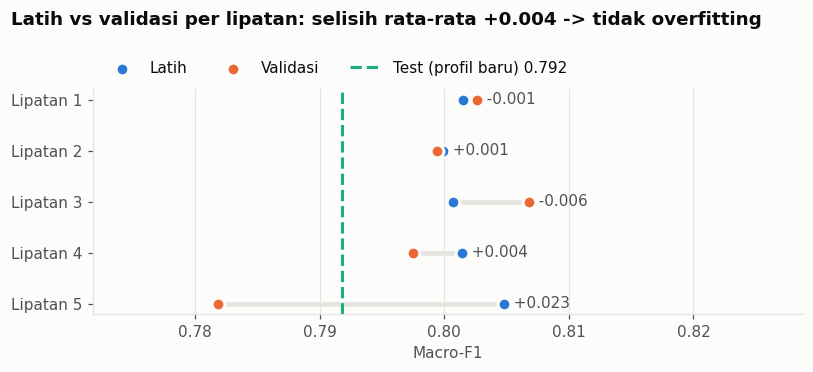

In [4]:
display(grafik.tabel_cv_per_fold(h))
grafik.latih_vs_validasi(h)

## 4. Cek overfitting

Overfitting = model menghafal data latih: skor latih jauh lebih tinggi daripada skor data baru.
Ukurannya adalah **selisih macro-F1 latih − validasi/test**:

| Selisih | Kesimpulan |
|---|---|
| ≤ 0,02 | tidak overfitting |
| ≤ 0,05 | overfitting ringan |
| > 0,05 | overfitting |

Bila skor latih **dan** validasi sama-sama rendah, masalahnya underfitting (model terlalu sederhana), bukan overfitting.
Gradient boosting ditampilkan sebagai pembanding model yang lebih kompleks.

accuracy  macro_f1  weighted_kappa  log_loss
Model               Data                                                                 
Logistic Regression Latih (model final)        0.8706    0.8013          0.8645    0.2795
                    Latih (rata-rata CV)       0.8710    0.8017          0.8649    0.2789
                    Validasi (rata-rata CV)    0.8683    0.7976          0.8613    0.2864
                    Test (profil baru)         0.8634    0.7918          0.8552    0.2881
Gradient boosting   Latih                      0.9781    0.9647          0.9772    0.0980
                    Test (profil baru)         0.9204    0.8766          0.9142    0.1960

Logistic Regression : selisih F1 latih-CV +0.0040, latih-test +0.0095 -> tidak overfitting
Gradient boosting   : selisih F1 latih-test +0.0881 -> overfitting


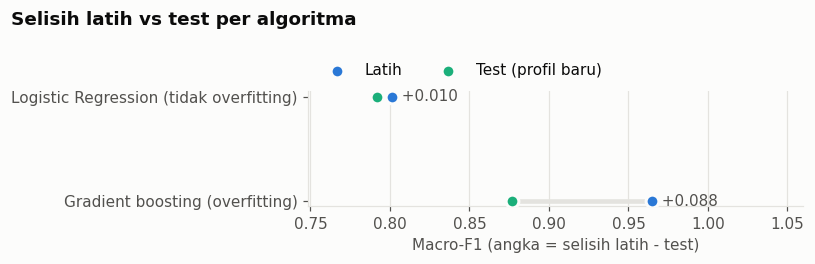

In [5]:
o = h['overfitting']
display(grafik.tabel_overfitting(h))
print(f"Logistic Regression : selisih F1 latih-CV {o['selisih_f1_train_vs_cv']:+.4f}, latih-test {o['selisih_f1_train_vs_test']:+.4f} -> {o['kesimpulan']}")
gb = o['pembanding_gradient_boosting']
print(f"Gradient boosting   : selisih F1 latih-test {gb['selisih_f1_train_vs_test']:+.4f} -> {gb['kesimpulan']}")
grafik.overfitting_lr_vs_gb(h)

### Kurva belajar

Model dilatih ulang dengan 10%..100% profil latih. Bila garis latih dan validasi bertemu di nilai tinggi, model
tidak overfitting; jarak lebar yang menetap = overfitting; keduanya rendah = underfitting.

,n_profil_latih,train_macro_f1,train_std,val_macro_f1,val_std
fraksi,,,,,
0.1,45,0.8152,0.0056,0.7796,0.0093
0.2,90,0.8130,0.0058,0.7900,0.0057
0.4,179,0.8061,0.0055,0.7960,0.0077
0.6,269,0.8037,0.0037,0.7962,0.0079
0.8,358,0.8027,0.0032,0.7971,0.0064
1.0,448,0.8017,0.0017,0.7976,0.0085


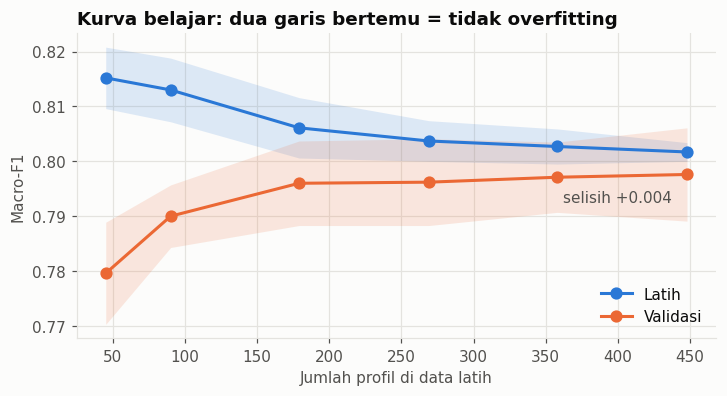

In [6]:
display(pd.DataFrame(h['kurva_belajar']).set_index('fraksi'))
grafik.kurva_belajar(h)

## 5. Test set (profil baru)

Accuracy 0.8634 | macro-F1 0.7918 | weighted kappa 0.8552 | log loss 0.2881
Subset makanan baru (tidak ada di data latih): macro-F1 0.7822 | kappa 0.8444


,precision,recall,f1,support
0 tidak sesuai,0.9455,0.9404,0.9429,5500.0
1 cukup,0.6862,0.7321,0.7084,1900.0
2 sangat sesuai,0.7631,0.6888,0.7240,996.0


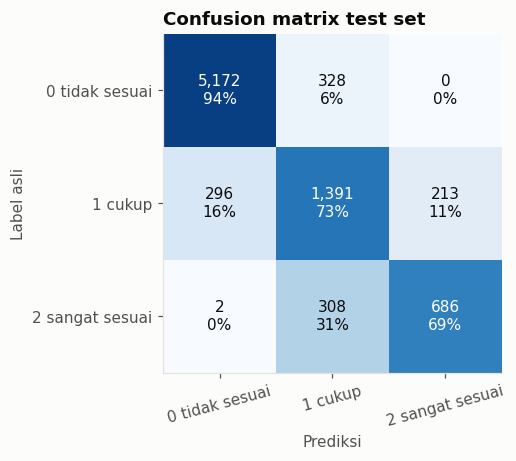

In [7]:
t = h['test']
print(f"Accuracy {t['accuracy']:.4f} | macro-F1 {t['macro_f1']:.4f} | weighted kappa {t['weighted_kappa']:.4f} | log loss {t['log_loss']:.4f}")
nf = h['test_new_food']
print(f"Subset makanan baru (tidak ada di data latih): macro-F1 {nf.get('macro_f1', 0):.4f} | kappa {nf.get('weighted_kappa', 0):.4f}")
display(grafik.tabel_per_kelas(h))
grafik.confusion(h)

## 6. Pembanding

,Accuracy,F1 (macro),Kappa,NDCG@5
Logistic Regression (model),0.8634,0.7918,0.8552,0.9560
Gradient boosting,0.9204,0.8766,0.9142,0.9765
Formula lama,NaN,NaN,NaN,0.6614
Urutan acak,NaN,NaN,NaN,0.5360


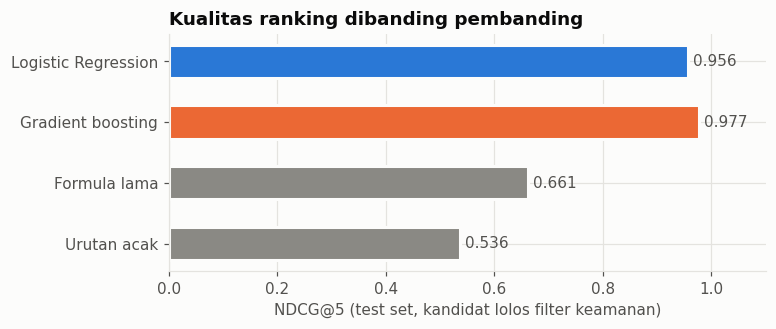

In [8]:
display(grafik.tabel_pembanding(h))
grafik.pembanding_ndcg(h)

## 7. Koefisien model

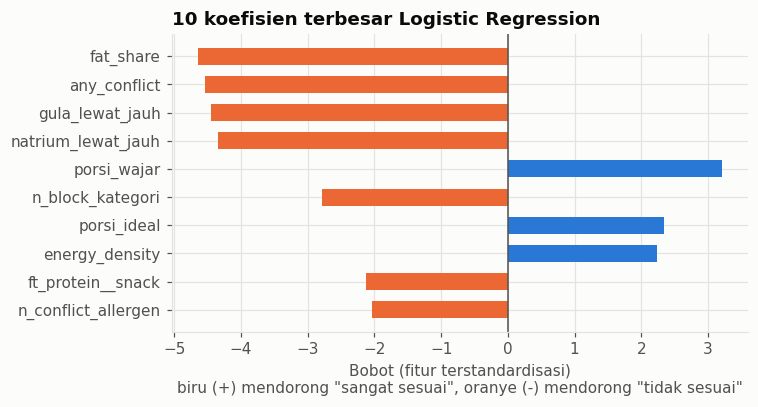

In [9]:
grafik.koefisien(h)

## 8. Uji end-to-end & laporan validasi

Skenario kategori dijalankan lewat pipeline produksi (filter keamanan + model + penyusun menu) memakai katalog
produk Supabase (atau snapshot lokal bila offline). Laporan disimpan ke `outputs/`.

In [10]:
path = validasi_kategori(KATEGORI)
with open(path, encoding='utf-8') as f:
    display(Markdown(f.read()))

[Pipeline] Memuat data makanan dari http://localhost:3000/api/products...


[Pipeline] Sukses memuat data makanan dari Next.js API (50 item).
[Pipeline] OK: 46 makanan siap dengan deteksi alergen & fitur ML.
[IBU_HAMIL] Acc 0.8634 | Prec 0.7983 | Recall 0.7871 | F1 0.7918 | Kappa 0.8552
[IBU_HAMIL] Pelanggaran alergen/BLOKIR/tekstur: 0/0/0
[IBU_HAMIL] Laporan: D:\Semester 6\Proyek Perangkat Lunak I\AINutriScale\ai_recommendation_railway\ibu_hamil\outputs\laporan_validasi_ibu_hamil.md


# Laporan Validasi Model IBU_HAMIL

- Pemilik: **Muz**
- Metode: Logistic Regression multinomial (label 0/1/2), metode dan konfigurasi sama dengan 3 kategori lain (config hash `7ec1c77b29e130d2`)
- Data: 560 profil latih (33586 pasangan), 140 profil uji baru (8396 pasangan); split per profil
- Evaluasi: validasi silang GroupKFold 5 lipatan pada data latih + test set profil baru (dipakai sekali untuk model final)
- Tanggal laporan: 2026-11-09

## 1. Metrik test set (profil baru)

| Accuracy | Precision (macro) | Recall (macro) | F1 (macro) | Weighted kappa | NDCG@5 | NDCG@10 |
|---|---|---|---|---|---|---|
| 0.8634 | 0.7983 | 0.7871 | 0.7918 | 0.8552 | 0.9560 | 0.9672 |

## 2. Validasi silang GroupKFold (5 lipatan, data latih)

| Metrik (validasi) | Rata-rata | Simpangan baku |
|---|---|---|
| accuracy | 0.8683 | 0.0071 |
| macro_f1 | 0.7976 | 0.0095 |
| weighted_kappa | 0.8613 | 0.0042 |
| log_loss | 0.2864 | 0.0104 |
| ndcg@5 | 0.9582 | 0.0031 |

## 3. Per kelas

| Kelas | Precision | Recall | F1 | Jumlah |
|---|---|---|---|---|
| 0 tidak cocok | 0.9455 | 0.9404 | 0.9429 | 5500 |
| 1 cukup | 0.6862 | 0.7321 | 0.7084 | 1900 |
| 2 sangat cocok | 0.7631 | 0.6888 | 0.7240 | 996 |

Confusion matrix (baris = label asli 0/1/2, kolom = prediksi 0/1/2):

| Asli \ Prediksi | 0 | 1 | 2 |
|---|---|---|---|
| 0 | 5172 | 328 | 0 |
| 1 | 296 | 1391 | 213 |
| 2 | 2 | 308 | 686 |

## 4. Pembanding

| Metode | Accuracy | F1 (macro) | Kappa | NDCG@5 |
|---|---|---|---|---|
| Logistic Regression (model) | 0.8634 | 0.7918 | 0.8552 | 0.9560 |
| Gradient boosting (pembanding) | 0.9204 | 0.8766 | 0.9142 | 0.9765 |
| Formula lama | - | - | - | 0.6614 |
| Urutan acak | - | - | - | 0.5360 |

- Subset makanan baru (tidak ada di data latih): macro-F1 0.7822, kappa 0.8444
- Pasangan konflik yang tetap diberi label > 0 oleh model saja: 0.00% (di produksi dibuang dulu oleh filter keamanan)

## 5. Analisis overfitting

Overfitting = skor data latih jauh lebih tinggi daripada data yang belum pernah dilihat. Batas selisih macro-F1: <= 0.02 tidak overfitting, <= 0.05 overfitting ringan, di atasnya overfitting.

| Model | Data | Accuracy | F1 (macro) | Kappa | Log loss |
|---|---|---|---|---|---|
| Logistic Regression | Latih (model final) | 0.8706 | 0.8013 | 0.8645 | 0.2795 |
| Logistic Regression | Test (profil baru) | 0.8634 | 0.7918 | 0.8552 | 0.2881 |
| Gradient boosting | Latih | 0.9781 | 0.9647 | 0.9772 | 0.0980 |
| Gradient boosting | Test (profil baru) | 0.9204 | 0.8766 | 0.9142 | 0.1960 |

- Macro-F1 GroupKFold: latih 0.8017 vs validasi 0.7976 (selisih +0.0040)
- Macro-F1 model final: latih 0.8013 vs test 0.7918 (selisih +0.0095)
- **Kesimpulan Logistic Regression: tidak overfitting**; gradient boosting: overfitting (selisih +0.0881)

Per lipatan GroupKFold:

| Lipatan | F1 latih | F1 validasi | Selisih | Log loss latih | Log loss validasi |
|---|---|---|---|---|---|
| 1 | 0.8015 | 0.8026 | -0.0011 | 0.2779 | 0.2907 |
| 2 | 0.7999 | 0.7994 | +0.0005 | 0.2782 | 0.2884 |
| 3 | 0.8007 | 0.8068 | -0.0061 | 0.2809 | 0.2780 |
| 4 | 0.8014 | 0.7975 | +0.0039 | 0.2817 | 0.2744 |
| 5 | 0.8048 | 0.7818 | +0.0230 | 0.2757 | 0.3004 |

Kurva belajar (macro-F1, rata-rata 5 lipatan GroupKFold):

| Porsi data latih | Profil | F1 latih | F1 validasi | Selisih |
|---|---|---|---|---|
| 10% | 45 | 0.8152 | 0.7796 | +0.0356 |
| 20% | 90 | 0.8130 | 0.7900 | +0.0230 |
| 40% | 179 | 0.8061 | 0.7960 | +0.0101 |
| 60% | 269 | 0.8037 | 0.7962 | +0.0075 |
| 80% | 358 | 0.8027 | 0.7971 | +0.0056 |
| 100% | 448 | 0.8017 | 0.7976 | +0.0041 |

## 6. Koefisien teratas (arah sangat cocok vs tidak cocok)

| Fitur | Bobot |
|---|---|
| fat_share | -4.6453 |
| any_conflict | -4.5357 |
| gula_lewat_jauh | -4.4477 |
| natrium_lewat_jauh | -4.3371 |
| porsi_wajar | 3.2051 |
| n_block_kategori | -2.7776 |
| porsi_ideal | 2.3452 |
| energy_density | 2.2418 |
| ft_protein__snack | -2.1208 |
| n_conflict_allergen | -2.04 |

## 7. Uji end-to-end (filter keamanan + model + penyusun menu, katalog Supabase)

| Skenario | Item | Kandidat lolos | Alergen | BLOKIR | Tekstur | Skor rata-rata | Latensi (ms) |
|---|---|---|---|---|---|---|---|
| Ibu Hamil T3 | 11 | 43 | 0 | 0 | 0 | 68.8 | 57.7 |
| Ibu Hamil T1 Alergi Susu | 11 | 41 | 0 | 0 | 0 | 73.3 | 64.7 |

**Ibu Hamil T3**: pagi: karbo: Oatmeal, lauk: Kidney Beans, buah/sayur: Banana; snack_pagi: selingan: Baked Potato Chips; siang: karbo: Whole Wheat Bread, lauk: Fresh Chicken Breast, sayur: Sweet Potato; snack_sore: selingan: Ajwa Dates; malam: karbo: Quinoa, lauk: Lentils, sayur: Broccoli

**Ibu Hamil T1 Alergi Susu**: pagi: karbo: Oatmeal, lauk: Tilapia Fish, buah/sayur: Banana; snack_pagi: selingan: Ajwa Dates; siang: karbo: Quinoa, lauk: Fresh Chicken Breast, sayur: Sweet Potato; snack_sore: selingan: Baked Potato Chips; malam: karbo: Whole Wheat Bread, lauk: Mung Beans, sayur: Broccoli

## 8. Catatan

Data sintetis dan label dari rubrik kategori (ibu_hamil/ai_models/rubrik.py). Angka di atas mengukur seberapa baik model meniru rubrik, bukan hasil uji klinis. Karena data latih dan test dibuat dari rubrik yang sama, selisih latih-test yang kecil membuktikan model tidak menghafal profil/makanan tertentu, tetapi belum membuktikan kecocokan dengan pengguna nyata. Diperlukan gold set ahli gizi (minimal 300 pasangan) sebelum klaim klinis.
